# 07 · Evaluate free-running rollouts

Predict repeatedly by feeding model outputs back into the context. No future observed states are supplied.

**Run cells in order.** The default smoke preset validates the pipeline; it is too small for a scientific conclusion.

## Setup

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'twilight_moe').exists(), 'Start Jupyter from the project folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.plotting import style, save_figure, COLORS
cfg = load_config()
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'])
print('Dataset root:', cfg['data_root'])

Preset: experiment | seeds: [7, 17, 27]
Dataset root: E:/HarunoKen/Twilight_MoE_Dynamics


## Load rollout errors

Targets do not overlap within each sequence. The oracle is additionally supplied future true regimes.

In [2]:
from twilight_moe.experiment import load_diagnostics, load_metrics
from twilight_moe.models import MODEL_NAMES
results = load_metrics(cfg)
curves = {name: np.stack([load_diagnostics(cfg, name, seed)['rollout_mse']
                          for seed in cfg['seeds']]) for name in MODEL_NAMES}
horizon = np.arange(1, cfg['evaluation']['rollout_horizon']+1)

## Plot errors by forecast horizon

Lines are seed means. Light lines show individual seeds when multiple seeds are present.

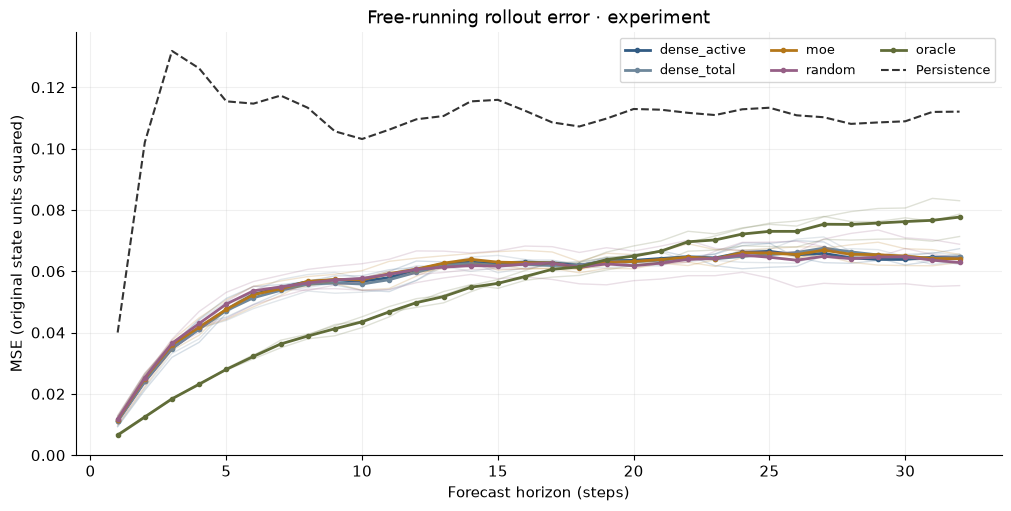

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in MODEL_NAMES:
    if len(cfg['seeds']) > 1:
        for curve in curves[name]:
            ax.plot(horizon, curve, color=COLORS[name], alpha=.2, linewidth=1)
    ax.plot(horizon, curves[name].mean(0), color=COLORS[name], label=name, marker='.', linewidth=2)
persistence = np.stack([load_diagnostics(cfg, 'moe', seed)['rollout_persistence'] for seed in cfg['seeds']]).mean(0)
ax.plot(horizon, persistence, color='#333333', linestyle='--', label='Persistence')
ax.set(title=f'Free-running rollout error · {cfg["name"]}', xlabel='Forecast horizon (steps)',
       ylabel='MSE (original state units squared)', ylim=(0, None))
ax.legend(ncol=3, fontsize=9)
save_figure(fig, cfg, 'rollout_error')
plt.show()

## Compare average rollout errors

Average error weights each horizon equally. It differs from one-step error over all windows.

In [4]:
display(results[['model', 'seed', 'rollout_mean_mse', 'rollout_origins']].round(6))
print('Metrics and diagnostics:', run_dir(cfg))
print('Figures:', ROOT / 'results' / 'figures' / run_dir(cfg).name)

,model,seed,rollout_mean_mse,rollout_origins
0,dense_active,7,0.056849,320
1,dense_total,7,0.056188,320
2,moe,7,0.056010,320
3,random,7,0.052335,320
4,oracle,7,0.051574,320
5,dense_active,17,0.057297,320
6,dense_total,17,0.057144,320
7,moe,17,0.059854,320
8,random,17,0.061657,320
9,oracle,17,0.056069,320


Metrics and diagnostics: D:\HarunoKen\Twilight_MoE_Dynamics\results\metrics\experiment_57adae732ea0
Figures: D:\HarunoKen\Twilight_MoE_Dynamics\results\figures\experiment_57adae732ea0


## Takeaways and next experiment

Long-horizon prediction becomes uncertain as regimes switch and noise accumulates. An eventually flat error curve can reflect regression toward the mean. Next, run the larger preset unchanged, compare paired seeds, and then plan a preregistered parameter sweep. SAE and DAS remain future work.